# 06 · Modelling with a Custom Asymmetric Loss: **HALO**
**HALO = Heat-Adaptive, Load-aware LINEX Objective.** Full derivation: `src/heatwave_peak/losses.py`.

### 1. The cost of a miss is asymmetric and convex
| Miss | What the grid does | Approx. cost |
|------|--------------------|-------------|
| 5 GW **surplus** | backs down thermal units it had scheduled, still pays capacity charges | ~Rs 2.5/kWh |
| 5 GW **shortfall**, within reserves | uses secondary/tertiary reserves (~3-5 % of demand) | moderate |
| 5 GW+ **shortfall**, beyond reserves | buys in the real-time market at the **Rs 10/kWh cap**, or sheds load in 45 C heat | very high |

### 2. The loss
With $e = y - \hat y$ (in % of the weekly base; $e>0$ means **under**-forecast):
$$L(e) = \frac{e^{a_i e} - a_i e - 1}{a_i^2}, \qquad a_i = a_0 + a_{heat}\, s_i + a_{scarcity}\, g_i$$
* small errors: $L \approx e^2/2$, i.e. **MSE**, so ordinary-day accuracy is kept
* big shortfalls grow **exponentially**, big surpluses only **linearly**
* $s_i$ = heat severity (IMD + EHF, demand-weighted); $g_i$ = closeness of the true peak to the 365-day record (scarcity)

### 3. Why it beats a quantile loss and the prototype
* The optimal LINEX forecast is $\mu + \tfrac{a}{2}\sigma^2$: the **safety margin scales with uncertainty**. Heatwave days are both
  costlier (bigger $a$) and harder to predict (bigger $\sigma$), so they get the biggest margin, the way a careful operator sets reserves.
* The pinball loss is linear, so it cannot express "big misses are disproportionately bad", and it biases *every* day by the same quantile.
* The prototype used a 0/1 heatwave switch, one constant multiplier and a constant Hessian. HALO is continuous in severity,
  adds scarcity, and keeps the true curvature (exact Newton leaf values).

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

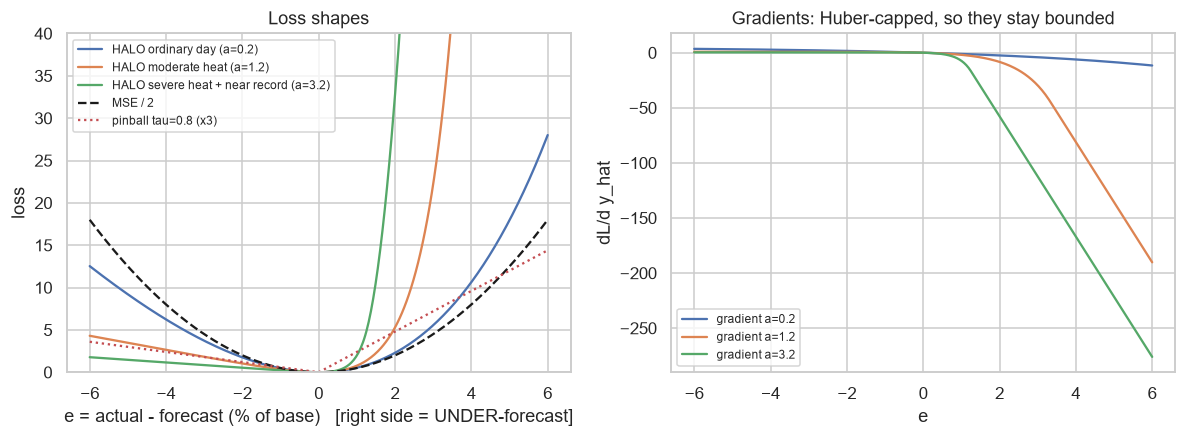

max |analytic - numerical gradient| = 9.010091162053868e-08


In [2]:
from heatwave_peak.losses import HALOObjective, numerical_gradient_check
o = HALOObjective(a0=0.2, a_heat=5, a_scarcity=2)
e = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a_, lab in [(0.2, "ordinary day (a=0.2)"), (1.2, "moderate heat (a=1.2)"), (3.2, "severe heat + near record (a=3.2)")]:
    ax[0].plot(e, o.loss(e, np.zeros_like(e), np.full_like(e, a_), np.ones_like(e)), label="HALO " + lab)
ax[0].plot(e, e ** 2 / 2, "k--", label="MSE / 2")
tau = .8; ax[0].plot(e, np.where(e > 0, tau * e, (tau - 1) * e) * 3, ":", label="pinball tau=0.8 (x3)")
ax[0].set(ylim=(0, 40), xlabel="e = actual - forecast (% of base)   [right side = UNDER-forecast]", ylabel="loss", title="Loss shapes")
ax[0].legend(fontsize=8)
for a_ in (0.2, 1.2, 3.2):
    g, h = o.grad_hess(e, np.zeros_like(e), np.full_like(e, a_), np.ones_like(e))
    ax[1].plot(e, g, label=f"gradient a={a_}")
ax[1].set(xlabel="e", ylabel="dL/d y_hat", title="Gradients: Huber-capped, so they stay bounded"); ax[1].legend(fontsize=8)
savefig("06_halo_loss_shapes"); plt.show()
print("max |analytic - numerical gradient| =", numerical_gradient_check(o))

### 4. The LINEX safety-margin property, checked numerically
For Gaussian outcomes the LINEX-optimal forecast should be $\mu + a\sigma^2/2$. We verify this by brute-force minimisation.

In [3]:
rng = np.random.default_rng(0)
rows = []
for sigma in (1.0, 2.0, 3.0):
    y = rng.normal(0, sigma, 200_000)
    for a_ in (0.2, 0.6):
        grid = np.linspace(-2, 6, 801)
        risk = [o.loss(y, np.full_like(y, c), np.full_like(y, a_), np.ones_like(y)).mean() for c in grid]
        rows.append({"sigma": sigma, "a": a_, "numerical optimum": grid[int(np.argmin(risk))], "theory a*sigma^2/2": a_ * sigma ** 2 / 2})
pd.DataFrame(rows).round(2)

,sigma,a,numerical optimum,theory a*sigma^2/2
0,1.0,0.2,0.10,0.1
1,1.0,0.6,0.30,0.3
2,2.0,0.2,0.40,0.4
3,2.0,0.6,1.20,1.2
4,3.0,0.2,0.91,0.9
5,3.0,0.6,2.69,2.7


## 5. Experiment protocol
* **Same** features, target, splits and tree hyper-parameters for every LightGBM model. **Only the loss changes.**
* Baselines: naive (same weekday last week), LightGBM-L2, LightGBM-quantile 0.8 (the cost-optimal quantile for a 10:2.5 cost ratio),
  the team's **prototype** objective, and plain **LINEX** (HALO with no heat/scarcity conditioning: an ablation).
* HALO's $(a_0, a_{heat}, a_{scarcity})$ are tuned on **2024** with this rule (revised once; see the README, section "Honest reporting"): *minimise grid cost on heat/critical-peak days subject to
  ordinary-day MAE <= 105 % of L2*. Then every model is refit on 2019-2024 and scored **once** on 2025.
* A walk-forward backtest (test years 2022-2025) checks robustness.

The next cell runs the whole experiment (~5-10 min) and saves models, predictions and metrics.

In [4]:
from heatwave_peak import experiment as EX
res = EX.run_full_experiment(verbose=False)
print("selected HALO parameters:", res["halo_params"])
print("boosting rounds:", res["rounds"])

selected HALO parameters: {'a0': 0.2, 'a_heat': 12.0, 'a_scarcity': 6.0}
boosting rounds: {'lgbm_l2': 700, 'lgbm_quantile60': 3999, 'lgbm_quantile80': 915, 'lgbm_prototype': 700, 'lgbm_linex': 381, 'lgbm_halo': 373}


## 6. Tuning results on the 2024 validation year

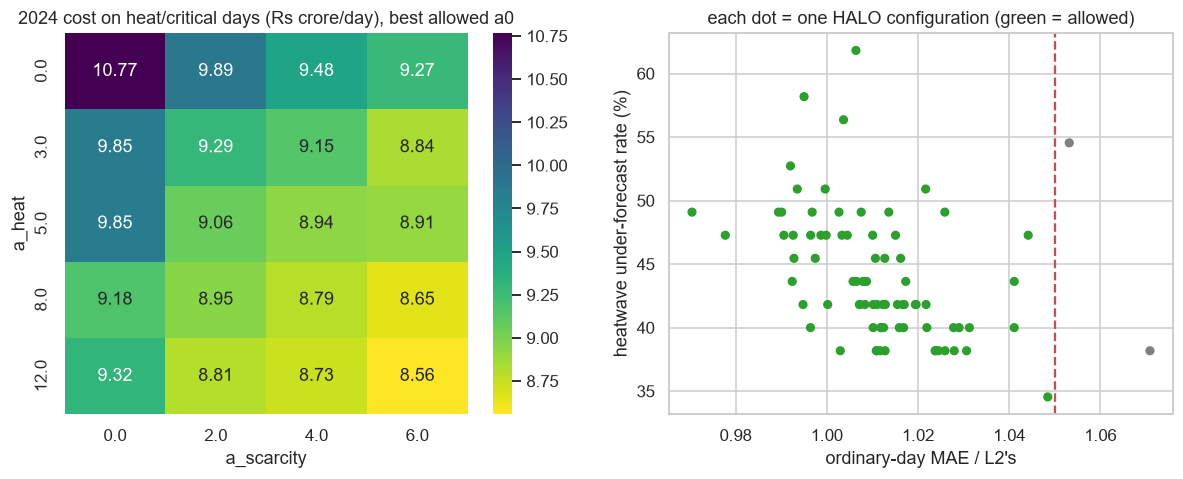

,a0,a_heat,a_scarcity,best_iter,cost_all,cost_hw_or_critical,MAPE_all,MAE_ordinary,MAE_hw,under_rate_hw,under_rate_critical,reserve_breach_all,ordinary_mae_ratio_vs_l2
59,0.20,12.0,6.0,373,6.310,8.557,1.481,2808.446,4327.083,38.182,60.000,2.732,1.003
75,0.30,8.0,6.0,320,6.238,8.653,1.507,2872.726,4293.190,38.182,60.000,2.732,1.026
79,0.30,12.0,6.0,312,6.345,8.694,1.547,2935.863,4505.516,34.545,56.667,2.459,1.048
55,0.20,8.0,6.0,344,6.308,8.705,1.481,2828.651,4212.838,40.000,61.667,3.005,1.010
19,0.05,12.0,6.0,324,6.607,8.714,1.497,2844.689,4381.038,40.000,61.667,2.186,1.016
58,0.20,12.0,4.0,371,6.435,8.730,1.494,2835.038,4364.313,40.000,61.667,2.186,1.012
38,0.10,12.0,4.0,370,6.568,8.765,1.488,2830.574,4337.034,38.182,60.000,2.732,1.011
18,0.05,12.0,4.0,362,6.673,8.766,1.488,2831.012,4326.408,41.818,63.333,3.279,1.011


In [5]:
tun = res["tuning"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pv = tun[tun.ordinary_mae_ratio_vs_l2 <= EX.MAX_ORDINARY_MAE_RATIO].groupby(["a_heat", "a_scarcity"]).cost_hw_or_critical.min().unstack()
sns.heatmap(pv, annot=True, fmt=".2f", cmap="viridis_r", ax=ax[0]); ax[0].set_title("2024 cost on heat/critical days (Rs crore/day), best allowed a0")
feas = tun.ordinary_mae_ratio_vs_l2 <= EX.MAX_ORDINARY_MAE_RATIO
ax[1].scatter(tun.ordinary_mae_ratio_vs_l2, tun.under_rate_hw, c=np.where(feas, "tab:green", "tab:grey"), s=25)
ax[1].axvline(EX.MAX_ORDINARY_MAE_RATIO, color="r", ls="--"); ax[1].set(xlabel="ordinary-day MAE / L2's", ylabel="heatwave under-forecast rate (%)",
          title="each dot = one HALO configuration (green = allowed)")
savefig("06_halo_tuning"); plt.show()
tun[tun.ordinary_mae_ratio_vs_l2 <= EX.MAX_ORDINARY_MAE_RATIO].sort_values("cost_hw_or_critical").head(8).round(3)

## 7. Validation (2024) comparison of all models

In [6]:
show = ["model", "regime", "n_days", "MAE_MW", "MAPE_pct", "R2", "bias_MW", "under_rate_pct", "mean_shortfall_MW", "reserve_breach_pct", "cost_crore_per_day"]
vm = res["val_metrics"]
vm[vm.regime.isin(["all", "ordinary", "heatwave", "critical_peak"])][show].round(2)

,model,regime,n_days,MAE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,reserve_breach_pct,cost_crore_per_day
0,naive_lag7,all,366.0,7543.79,3.63,0.23,-9.96,54.92,6877.30,23.22,18.87
1,naive_lag7,ordinary,311.0,7119.12,3.48,-0.06,540.29,53.05,6200.05,20.26,16.99
2,naive_lag7,heatwave,55.0,9945.12,4.49,-0.01,-3121.40,65.45,9981.37,40.00,29.54
3,naive_lag7,critical_peak,60.0,8571.08,3.77,-1.03,-5790.32,81.67,8792.69,45.00,30.11
5,lgbm_l2,all,366.0,3002.41,1.45,0.84,-14.16,53.55,2816.49,4.37,7.53
6,lgbm_l2,ordinary,311.0,2800.17,1.37,0.79,83.70,52.41,2591.47,3.22,6.87
7,lgbm_l2,heatwave,55.0,4146.01,1.92,0.75,-567.55,60.00,3927.97,10.91,11.22
8,lgbm_l2,critical_peak,60.0,3184.98,1.41,0.74,-2180.10,75.00,3576.72,8.33,11.23
10,lgbm_quantile60,all,366.0,3048.83,1.49,0.83,664.64,49.18,2423.93,2.46,6.63
11,lgbm_quantile60,ordinary,311.0,2889.42,1.43,0.77,751.55,48.55,2201.59,1.61,6.10


In [7]:
for name, m in res["final_models"].items():
    print(f"{name:<16} rounds={m.best_iter:>5}  saved -> models/{name}.txt")

lgbm_l2          rounds=  700  saved -> models/lgbm_l2.txt
lgbm_quantile60  rounds= 3999  saved -> models/lgbm_quantile60.txt
lgbm_quantile80  rounds=  915  saved -> models/lgbm_quantile80.txt
lgbm_prototype   rounds=  700  saved -> models/lgbm_prototype.txt
lgbm_linex       rounds=  381  saved -> models/lgbm_linex.txt
lgbm_halo        rounds=  373  saved -> models/lgbm_halo.txt
